# Práctica 3: Tarea de clasificación

César Eduardo Jardines Mendoza
Cuatrimestre III-2026
CICESE

### Descripción del contexto y procedencia del dataset

Para esta práctica se utilizó el dataset *Predict Students' Dropout and Academic Success*, el cual se encuentra disponible en el repositorio de aprendizaje automático de la UCI (https://archive.ics.uci.edu/dataset/697). Fue donado en diciembre del 2021 por investigadores del Instituto Politécnico de Portalegre, en Portugal, y se distribuye bajo la licencia CC BY 4.0 (Realinho et al., 2021).


En total son 4424 estudiantes que ingresaron entre los ciclos 2008/09 y 2018/19. Cada registro representa a un estudiante y está descrito por 36 atributos que podemos agrupar en tres tipos de información: la que se conoce al momento de la inscripción (trayectoria académica previa, datos demográficos y factores socioeconómicos), el desempeño académico al cierre del primer y segundo semestre, y tres indicadores macroeconómicos (tasa de desempleo, inflación y PIB). La variable objetivo *Target* indica la situación del estudiante al final de la duración normal de su carrera: *Graduate*, *Dropout* o *Enrolled*.

Para la práctica el dataset ya viene dividido en dos archivos. El conjunto de entrenamiento (`desercion-entrenamiento.csv`) tiene 3539 estudiantes con los 36 atributos, la variable *Target* y una columna `id`, mientras que el conjunto de prueba (`desercion-prueba.csv`) tiene 885 estudiantes sin *Target* y solo con los atributos que se conocen al cierre del primer semestre. Entonces las seis columnas de `Curricular units 2nd sem` únicamente aparecen en entrenamiento, y esto es importante porque el modelo final solo puede usar los 30 atributos que también están en prueba.

Al revisar los archivos encontramos algunos puntos a considerar antes de construir los modelos:

- No hay valores faltantes en ninguno de los dos conjuntos.
- Las clases no están balanceadas: *Graduate* representa el 49.9 %, *Dropout* el 32.1 % y *Enrolled* solo el 17.9 %, por lo que esta última será la clase más difícil de predecir. Como el F1 macro le da el mismo peso a las tres clases, este desbalance tiene un efecto directo en la métrica.
- Varios atributos nominales vienen codificados como números enteros (por ejemplo `Course`, `Nacionality` o la ocupación de los padres), es decir, el número es solo una etiqueta y no representa una magnitud. De los 30 atributos disponibles, 9 son nominales, 8 son binarios y 13 son numéricos.
- El conjunto de prueba trae algunos códigos que no aparecen en entrenamiento, por ejemplo en `Nacionality`, `Application mode` y en las calificaciones y ocupaciones de los padres, así pues la codificación debe estar preparada para recibir categorías no vistas.
- La columna `id` no aporta información para predecir, solo se usará para generar el archivo de predicciones.
- *Target* viene con la primera letra en mayúscula (`Graduate`, `Dropout`, `Enrolled`), pero la entrega pide los valores en minúscula, así que habrá que convertirlos al momento de generar el CSV final.
- El atributo `Nacionality` viene escrito así en el dataset original, por lo que se conserva el nombre tal cual.



## 1. Carga y descripción de los datos

En esta fase cargamos los dos conjuntos, revisamos cómo se distribuyen las clases y clasificamos cada atributo según su tipo y el momento en que se conoce. Con base en esto definimos qué información se puede usar para construir los modelos.

Primero preparamos el entorno de trabajo. Importamos las librerías, fijamos la semilla de aleatoriedad para que los resultados se puedan reproducir y mostramos las versiones utilizadas.

In [58]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

SEED = 42
np.random.seed(SEED)

print("Python      ", sys.version.split()[0])
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("matplotlib  ", matplotlib.__version__)
print("scikit-learn", sklearn.__version__)

Python       3.13.18
numpy        2.4.6
pandas       2.2.3
matplotlib   3.10.0
scikit-learn 1.6.1


Cargamos los dos archivos usando rutas relativas y verificamos sus dimensiones, así como la presencia de valores faltantes.

In [59]:
train = pd.read_csv("desercion-entrenamiento.csv")
test = pd.read_csv("desercion-prueba.csv")

print("Entrenamiento:", train.shape, "| Prueba:", test.shape)
print("Valores faltantes:", train.isna().sum().sum(), "/", test.isna().sum().sum())

Entrenamiento: (3539, 38) | Prueba: (885, 31)
Valores faltantes: 0 / 0


Revisamos la distribución de la variable objetivo. Podemos observar el desbalance entre las clases, siendo *Enrolled* la clase minoritaria.

,n,%
Target,,
Graduate,1767,49.9
Dropout,1137,32.1
Enrolled,635,17.9


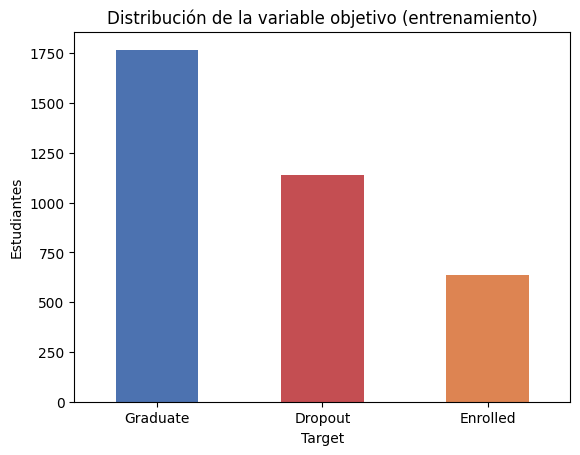

In [60]:
conteo = train["Target"].value_counts()
display(pd.DataFrame({"n": conteo, "%": (100 * conteo / len(train)).round(1)}))

conteo.plot.bar(rot=0, color=["#4c72b0", "#c44e52", "#dd8452"])
plt.title("Distribución de la variable objetivo (entrenamiento)")
plt.ylabel("Estudiantes")
plt.show()

Clasificamos cada atributo como nominal, binario o numérico, e identificamos en qué momento se conoce: al ingreso, al cierre del primer semestre o al cierre del segundo. Los atributos disponibles al momento de decidir son los mismos que trae el conjunto de prueba.

In [61]:
NOMINALES = ["Marital status", "Application mode", "Course", "Previous qualification",
             "Nacionality", "Mother's qualification", "Father's qualification",
             "Mother's occupation", "Father's occupation"]
BINARIAS = ["Daytime/evening attendance", "Displaced", "Educational special needs",
            "Debtor", "Tuition fees up to date", "Gender", "Scholarship holder",
            "International"]
SEGUNDO_SEM = [c for c in train.columns if "2nd sem" in c]

# Atributos disponibles al cierre del primer semestre = los que trae prueba
ATRIBUTOS = [c for c in test.columns if c != "id"]
NUMERICAS = [c for c in ATRIBUTOS if c not in NOMINALES + BINARIAS]

def tipo(c):
    if c in NOMINALES: return "nominal (código entero)"
    if c in BINARIAS:  return "binaria"
    return "numérica"

def momento(c):
    if "1st sem" in c: return "1er semestre"
    if "2nd sem" in c: return "2do semestre (solo entrenamiento)"
    if c in ["Unemployment rate", "Inflation rate", "GDP"]: return "macroeconómico (al ingreso)"
    return "al ingreso"

tabla = pd.DataFrame({"atributo": ATRIBUTOS + SEGUNDO_SEM})
tabla["tipo"] = tabla["atributo"].map(tipo)
tabla["momento"] = tabla["atributo"].map(momento)
tabla["valores distintos"] = tabla["atributo"].map(train.nunique())
display(tabla)
print(f"{len(NOMINALES)} nominales, {len(BINARIAS)} binarias, {len(NUMERICAS)} numéricas "
      f"→ {len(ATRIBUTOS)} atributos disponibles al decidir")

,atributo,tipo,momento,valores distintos
0,Marital status,nominal (código entero),al ingreso,6
1,Application mode,nominal (código entero),al ingreso,17
2,Application order,numérica,al ingreso,8
3,Course,nominal (código entero),al ingreso,17
4,Daytime/evening attendance,binaria,al ingreso,2
5,Previous qualification,nominal (código entero),al ingreso,17
6,Previous qualification (grade),numérica,al ingreso,100
7,Nacionality,nominal (código entero),al ingreso,18
8,Mother's qualification,nominal (código entero),al ingreso,26
9,Father's qualification,nominal (código entero),al ingreso,32


9 nominales, 8 binarias, 13 numéricas → 30 atributos disponibles al decidir


Verificamos si el conjunto de prueba contiene códigos de atributos nominales que no aparecen en entrenamiento.

In [62]:
for c in NOMINALES:
    nuevas = sorted(set(test[c]) - set(train[c]))
    if nuevas:
        print(f"{c}: {nuevas}")

Application mode: [26]
Nacionality: [13, 14, 32]
Mother's qualification: [10, 18, 27]
Father's qualification: [13, 18]
Mother's occupation: [171]
Father's occupation: [101]


Separamos los atributos de la variable objetivo. La matriz `X_2sem`, que incluye las columnas del segundo semestre, se reserva únicamente para el experimento que estima cuánto mejoraría el modelo si se esperara al cierre del segundo semestre.

In [63]:
X = train[ATRIBUTOS]
y = train["Target"]
X_test = test[ATRIBUTOS]
X_2sem = train[ATRIBUTOS + SEGUNDO_SEM]

## 2. Validación cruzada y preprocesamiento común

En este paso definimos los elementos que van a compartir. El orden pide que los cinco usen los mismos pliegues, entonces los generamos una sola vez y los guardamos, de esta forma las diferencias entre modelos se deben al modelo y no a la partición de los datos. También definimos el preprocesamiento base, una función para realizar las búsquedas y una línea base que nos sirve de referencia.

Generamos 5 pliegues estratificados sobre el conjunto de entrenamiento y los guardamos en una lista para reutilizarlos en todos los clasificadores. Verificamos que cada pliegue conserve la proporción de las clases.

In [64]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
FOLDS = list(cv.split(X, y))

proporciones = pd.DataFrame({
    f"Pliegue {i + 1}": y.iloc[val].value_counts(normalize=True).round(3)
    for i, (_, val) in enumerate(FOLDS)
})
display(proporciones)

,Pliegue 1,Pliegue 2,Pliegue 3,Pliegue 4,Pliegue 5
Target,,,,,
Graduate,0.500,0.500,0.499,0.499,0.499
Dropout,0.321,0.321,0.322,0.322,0.321
Enrolled,0.179,0.179,0.179,0.179,0.180


Definimos una función que construye el preprocesamiento por tipo de atributo. Los atributos nominales se codifican con one-hot, ya que el número que los representa es solo una etiqueta. Las categorías con menos de 10 estudiantes se agrupan en una sola columna para no generar columnas casi vacías, y las categorías que no aparecen en entrenamiento se envían a ese mismo grupo o se ignoran. Los atributos binarios se dejan como están. Los numéricos se estandarizan solo para los modelos que dependen de la escala (kNN, SVM y regresión logística), mientras que el árbol no lo necesita porque sus cortes no cambian al escalar.

In [65]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def preprocesador(escalar=True):
    return ColumnTransformer([
        ("nominales", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10), NOMINALES),
        ("binarias", "passthrough", BINARIAS),
        ("numericas", StandardScaler() if escalar else "passthrough", NUMERICAS),
    ])

Xt = preprocesador().fit_transform(X)
print("Columnas después del preprocesamiento:", Xt.shape[1])

Columnas después del preprocesamiento: 125


Para no repetir código definimos una función que realiza la búsqueda aleatoria de hiperparámetros con los pliegues fijos y el F1 macro como métrica. La función mide el tiempo de la búsqueda y guarda los resultados para la comparación final.

In [66]:
import time
from sklearn.model_selection import RandomizedSearchCV

RESULTADOS = {}

def buscar(nombre, pipeline, espacio, n_iter=60):
    busqueda = RandomizedSearchCV(pipeline, espacio, n_iter=n_iter, scoring="f1_macro",
                                  cv=FOLDS, random_state=SEED, n_jobs=-1)
    inicio = time.perf_counter()
    busqueda.fit(X, y)
    duracion = time.perf_counter() - inicio

    RESULTADOS[nombre] = {"busqueda": busqueda, "tiempo": duracion}
    i = busqueda.best_index_
    print(f"{nombre}: {len(busqueda.cv_results_['params'])} configuraciones evaluadas")
    print(f"  F1 macro = {busqueda.best_score_:.4f} ± {busqueda.cv_results_['std_test_score'][i]:.4f}")
    print(f"  Tiempo   = {duracion:.1f} s")
    print(f"  Mejores hiperparámetros: { {k: v for k, v in busqueda.best_params_.items() if k != 'prep'} }")
    return busqueda

Como referencia evaluamos dos clasificadores triviales:
- El que siempre predice la clase mayoritaria
- El que predice al azar respetando la proporción de las clases.

Cualquier modelo que construyamos debe superar claramente estos valores.

In [67]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score

for estrategia in ["most_frequent", "stratified"]:
    f1 = cross_val_score(DummyClassifier(strategy=estrategia, random_state=SEED),
                         X, y, cv=FOLDS, scoring="f1_macro")
    print(f"{estrategia:14s} F1 macro = {f1.mean():.4f} ± {f1.std():.4f}")

most_frequent  F1 macro = 0.2220 ± 0.0002
stratified     F1 macro = 0.3290 ± 0.0166


### Decisiones tomadas en esta fase

Durante la construcción de la validación cruzada y del preprocesamiento base se tomaron algunas decisiones que vale la pena justificar, ya que afectan a los cinco clasificadores por igual.

**Pliegues guardados en una lista.** Aunque al usar `StratifiedKFold` con una semilla fija se obtendrían los mismos pliegues cada vez que se llame, se decidió generarlos una sola vez y guardarlos en la lista `FOLDS`. De esta forma queda explícito que los cinco clasificadores se evalúan exactamente sobre las mismas particiones, y la comparación entre ellos no depende de que la semilla se conserve en cada llamada. Así pues, cualquier diferencia en el desempeño se debe al modelo y no a la forma en que se dividieron los datos.

**Agrupación de categorías poco frecuentes (`min_frequency=10`).** Algunos atributos nominales, como la ocupación de los padres, tienen muchas categorías y varias de ellas aparecen solo en uno o dos estudiantes. Una categoría con tan pocos ejemplos no permite identificar un patrón confiable, y al codificarla con one-hot solo agrega una columna casi vacía. Por eso se decidió agrupar en una sola columna las categorías con menos de 10 estudiantes. Este valor no es un número exacto ni óptimo, es una decisión razonable que reduce dimensiones sin eliminar las categorías más representativas. Además, esta misma agrupación permite manejar los códigos del conjunto de prueba que no aparecen en entrenamiento.

**Número de configuraciones evaluadas (`n_iter=60`).** La consigna pide evaluar al menos 50 configuraciones por clasificador, entonces se fijó la búsqueda aleatoria en 60 para cumplir con ese mínimo con un pequeño margen. Es importante considerar que, si el espacio de búsqueda de algún clasificador es completamente discreto y tiene menos de 60 combinaciones posibles, scikit-learn solo evalúa las que existen. Por esta razón, el espacio de búsqueda de cada clasificador se definió de forma que tuviera suficientes combinaciones para alcanzar el mínimo requerido.

## 3. Árbol de decisión

El árbol de decisión es el primer clasificador que optimizamos. Los atributos nominales sí se codifican con one-hot, porque si los dejamos como enteros el árbol podría hacer cortes como "`Course` < 9000", que no tienen sentido cuando el número es solo una etiqueta.

Definimos una función que genera las dos gráficas que muestran si la búsqueda llegó a una meseta. La primera muestra el mejor F1 macro alcanzado contra el número de configuraciones evaluadas: si la curva deja de subir, más configuraciones ya no mejoran el resultado. La segunda muestra el F1 macro de cada configuración contra su hiperparámetro más influyente.

In [68]:
from matplotlib.ticker import MaxNLocator

def graficar_busqueda(nombre, parametro, etiqueta, escala_log=False, entero=False):
    r = pd.DataFrame(RESULTADOS[nombre]["busqueda"].cv_results_)
    f1 = r["mean_test_score"].to_numpy()

    fig, ax = plt.subplots(1, 2, figsize=(13, 4))

    # Mejor F1 acumulado contra número de configuraciones
    ax[0].plot(np.arange(1, len(f1) + 1), np.maximum.accumulate(f1), marker=".")
    ax[0].set_xlabel("Configuraciones evaluadas")
    ax[0].set_ylabel("Mejor F1 macro alcanzado")
    ax[0].set_title(f"{nombre}: convergencia de la búsqueda")
    ax[0].grid(alpha=0.3)

    # F1 de cada configuración contra el hiperparámetro más influyente
    x = pd.to_numeric(r[f"param_{parametro}"], errors="coerce")
    hay_none = x.isna().any()
    if hay_none:                      # e.g. max_depth=None se grafica al final del eje
        valor_none = x.max() + 2
        x = x.fillna(valor_none)
    ax[1].scatter(x, f1, alpha=0.6)
    if entero:
        ax[1].xaxis.set_major_locator(MaxNLocator(integer=True))
    if pd.api.types.is_integer_dtype(r[f"param_{parametro}"].dropna().astype(object).map(type).eq(int).all() and "int") or hay_none:
        ax[1].xaxis.set_major_locator(MaxNLocator(integer=True))
    if hay_none:
        ticks = [t for t in ax[1].get_xticks() if 0 <= t < valor_none - 1]
        ax[1].set_xticks(ticks + [valor_none])
        ax[1].set_xticklabels([f"{t:g}" for t in ticks] + ["None"])
    if escala_log:
        ax[1].set_xscale("log")
    ax[1].set_xlabel(etiqueta)
    ax[1].set_ylabel("F1 macro de validación")
    ax[1].set_title(f"{nombre}: F1 macro contra {etiqueta}")
    ax[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

Construimos el Pipeline con el preprocesamiento sin escalamiento y el árbol de decisión. El espacio de búsqueda incluye el criterio de división (Gini o entropía), la profundidad máxima (de 2 a 20, o sin límite), dos formas de poda: el número mínimo de estudiantes por hoja (poda previa) y el parámetro `ccp_alpha` (poda por costo-complejidad, posterior), y los pesos por clase. Con `class_weight="balanced"` los errores en la clase minoritaria pesan más, lo cual puede ayudar a mejorar el F1 macro. Como el árbol se entrena rápido, se evaluaron 100 configuraciones.

In [69]:
from scipy.stats import randint, loguniform
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

pipe_arbol = Pipeline([
    ("prep", preprocesador(escalar=False)),
    ("modelo", DecisionTreeClassifier(random_state=SEED)),
])

espacio_arbol = {
    "modelo__criterion": ["gini", "entropy"],
    "modelo__max_depth": list(range(2, 21)) + [None],
    "modelo__min_samples_leaf": randint(1, 51),
    "modelo__ccp_alpha": loguniform(1e-5, 1e-2),
    "modelo__class_weight": [None, "balanced"],
}

busqueda_arbol = buscar("Árbol", pipe_arbol, espacio_arbol, n_iter=200)

Árbol: 200 configuraciones evaluadas
  F1 macro = 0.6457 ± 0.0102
  Tiempo   = 76.1 s
  Mejores hiperparámetros: {'modelo__ccp_alpha': np.float64(6.246073681318086e-05), 'modelo__class_weight': 'balanced', 'modelo__criterion': 'entropy', 'modelo__max_depth': 7, 'modelo__min_samples_leaf': 38}


Graficamos la convergencia de la búsqueda y el F1 macro contra la profundidad máxima, que resultó ser el hiperparámetro más influyente.

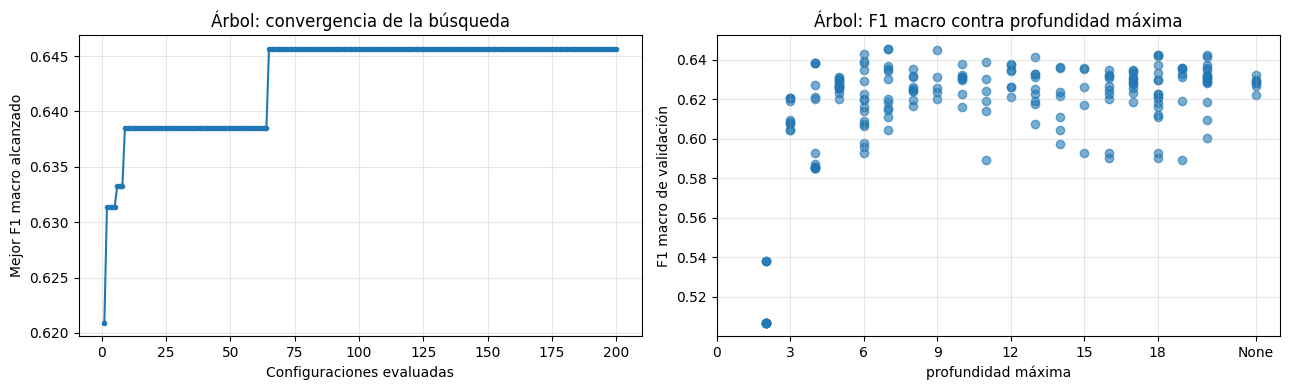

In [70]:
graficar_busqueda("Árbol", "modelo__max_depth", "profundidad máxima", entero=True)

### Resultados del árbol de decisión

El mejor árbol obtuvo un F1 macro de 0.6457 ± 0.0102, con criterio de entropía, profundidad máxima de 7, al menos 38 estudiantes por hoja, `ccp_alpha` ≈ 6.2 × 10⁻⁵ y pesos balanceados por clase.

En la gráfica de convergencia se observa que el F1 sube rápido en las primeras 10 configuraciones y después se mantiene casi sin cambios. Hay un último salto en la configuración 65, pero a partir de ahí se evaluaron 200 configuraciones restantes, entonces podemos decir que la búsqueda sí llegó a una meseta. Además, ese salto final es de apenas 0.007, que es menor que la desviación estándar entre pliegues (0.010), así pues la diferencia entre esa configuración y las anteriores está dentro de la variabilidad propia de la validación cruzada.

En la gráfica de profundidad se ve que los árboles con 2 niveles no logran separar bien las clases (F1 entre 0.50 y 0.54), pero a partir de 5 niveles el desempeño se estabiliza alrededor de 0.62–0.64 y aumentar la profundidad ya no ayuda. Incluso los árboles sin límite de profundidad quedan en el mismo rango, lo cual indica que las otras formas de poda están controlando el tamaño del árbol.

Es interesante que el mejor árbol pide hojas con al menos 38 estudiantes. Esto indica que conviene un árbol más simple, ya que las hojas con pocos estudiantes se ajustan demasiado a los datos de entrenamiento. Por otro lado, los pesos balanceados dieron mejores resultados que no usarlos, lo cual tiene sentido porque el F1 macro le da el mismo peso a la clase *Enrolled*, que es la minoritaria.

## 4. Naive Bayes

Naive Bayes supone que los atributos son independientes entre sí dada la clase, lo cual en este dataset no se cumple del todo (por ejemplo, las unidades inscritas, evaluadas y aprobadas del primer semestre están muy relacionadas). Aun así es un clasificador rápido y sirve como referencia. Como cada variante de Naive Bayes asume un tipo distinto de dato, la variante se eligió junto con su preprocesamiento dentro de la misma búsqueda.

Se consideraron dos formas de preparar los datos. Para la variante gaussiana, que asume que cada atributo sigue una distribución normal dentro de cada clase, se usa el mismo preprocesamiento que en los otros modelos, pero como matriz densa ya que `GaussianNB` no acepta matrices dispersas. Para las variantes Bernoulli, multinomial y complementaria, que trabajan con atributos discretos, los atributos numéricos se discretizan en intervalos con el mismo número de estudiantes (cuantiles) y cada intervalo se codifica con one-hot, de esta forma todos los atributos quedan como columnas de ceros y unos. El número de intervalos también se optimiza.

No se usó `CategoricalNB` porque falla cuando aparece una categoría que no vio en el entrenamiento, y el conjunto de prueba sí trae códigos nuevos.

Al discretizar, algunos atributos enteros con muchos valores repetidos (por ejemplo, unidades acreditadas, que casi siempre valen 0) no alcanzan el número de intervalos pedido y scikit-learn elimina los intervalos vacíos. Esto es esperado, por lo que se ocultan esas advertencias.

In [71]:
import warnings
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.naive_bayes import GaussianNB, BernoulliNB, MultinomialNB, ComplementNB

warnings.filterwarnings("ignore", message="Bins whose width are too small")
warnings.filterwarnings("ignore", message="The current default behavior, quantile_method")

prep_gaussiano = preprocesador(escalar=True).set_params(sparse_threshold=0)

prep_discreto = ColumnTransformer([
    ("nominales", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10), NOMINALES),
    ("binarias", "passthrough", BINARIAS),
    ("numericas", KBinsDiscretizer(n_bins=5, encode="onehot", strategy="quantile"), NUMERICAS),
])

El espacio de búsqueda se divide en dos partes. En la primera se usa la variante gaussiana con su parámetro de suavizado `var_smoothing`, que agrega una pequeña varianza a todos los atributos para evitar que una varianza casi nula domine la probabilidad. En la segunda se elige entre las variantes Bernoulli, multinomial y complementaria con su parámetro de suavizado `alpha` (suavizado de Laplace), que evita probabilidades de cero cuando una combinación de atributo y clase no aparece en el entrenamiento, junto con el número de intervalos de la discretización (de 3 a 15). Naive Bayes no admite pesos por clase. Se evaluaron 200 configuraciones.

In [72]:
pipe_nb = Pipeline([
    ("prep", prep_discreto),
    ("modelo", BernoulliNB()),
])

espacio_nb = [
    {
        "prep": [prep_gaussiano],
        "modelo": [GaussianNB()],
        "modelo__var_smoothing": loguniform(1e-12, 1e0),
    },
    {
        "prep": [prep_discreto],
        "prep__numericas__n_bins": randint(3, 16),
        "modelo": [BernoulliNB(), MultinomialNB(), ComplementNB()],
        "modelo__alpha": loguniform(1e-3, 1e2),
    },
]

busqueda_nb = buscar("Naive Bayes", pipe_nb, espacio_nb, n_iter=200)

Naive Bayes: 200 configuraciones evaluadas
  F1 macro = 0.6202 ± 0.0099
  Tiempo   = 53.8 s
  Mejores hiperparámetros: {'modelo': BernoulliNB(), 'modelo__alpha': np.float64(0.28006820077310235), 'prep__numericas__n_bins': 8}


Graficamos la convergencia de la búsqueda y el F1 macro contra el parámetro de suavizado, distinguiendo cada variante por color. En la variante gaussiana el suavizado es `var_smoothing` y en las demás es `alpha`, por eso ambos se muestran en el mismo eje con escala logarítmica.

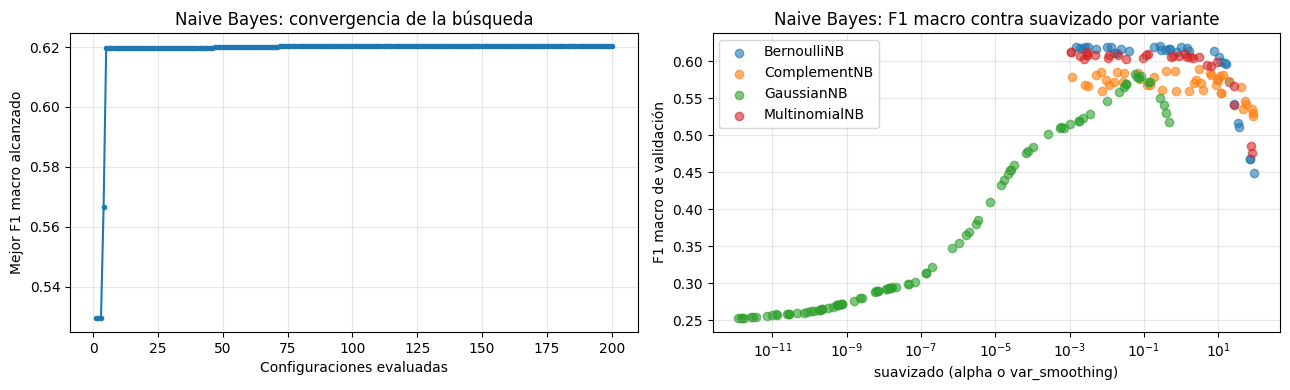

,count,mean,max
variante,,,
BernoulliNB,34,0.5916,0.6202
ComplementNB,44,0.5685,0.5892
GaussianNB,92,0.3704,0.5827
MultinomialNB,30,0.5941,0.6122


In [73]:
r = pd.DataFrame(busqueda_nb.cv_results_)
r["variante"] = r["param_modelo"].astype(str).str.split("(").str[0]
r["suavizado"] = (pd.to_numeric(r["param_modelo__alpha"], errors="coerce")
                    .fillna(pd.to_numeric(r["param_modelo__var_smoothing"], errors="coerce")))
f1 = r["mean_test_score"].to_numpy()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].plot(np.arange(1, len(f1) + 1), np.maximum.accumulate(f1), marker=".")
ax[0].set_xlabel("Configuraciones evaluadas")
ax[0].set_ylabel("Mejor F1 macro alcanzado")
ax[0].set_title("Naive Bayes: convergencia de la búsqueda")
ax[0].grid(alpha=0.3)

for variante, grupo in r.groupby("variante"):
    ax[1].scatter(grupo["suavizado"], grupo["mean_test_score"], alpha=0.6, label=variante)
ax[1].set_xscale("log")
ax[1].set_xlabel("suavizado (alpha o var_smoothing)")
ax[1].set_ylabel("F1 macro de validación")
ax[1].set_title("Naive Bayes: F1 macro contra suavizado por variante")
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

display(r.groupby("variante")["mean_test_score"].agg(["count", "mean", "max"]).round(4))

### Resultados de Naive Bayes

La mejor configuración fue la variante Bernoulli con `alpha` ≈ 0.28 y los atributos numéricos discretizados en 8 intervalos, con un F1 macro de 0.6202 ± 0.0099. Este resultado queda por debajo del árbol de decisión (0.6457), lo cual era de esperarse ya que el supuesto de independencia no se cumple en varios atributos.

En la gráfica de convergencia se observa que el mejor F1 se alcanza desde las primeras configuraciones y después solo mejora en milésimas, entonces la búsqueda llegó a una meseta muy pronto.

La gráfica del suavizado muestra que el hiperparámetro más influyente es la variante. Las variantes discretas (Bernoulli, multinomial y complementaria) se mantienen alrededor de 0.57–0.62, mientras que la variante gaussiana queda muy por debajo con valores de suavizado pequeños y solo se acerca a 0.58 cuando el suavizado es grande. Esto tiene sentido porque la mayoría de las columnas son de ceros y unos (por el one-hot y los atributos binarios), y suponer que esas columnas siguen una distribución normal no es adecuado. Así pues, discretizar los atributos numéricos fue una mejor decisión que asumir normalidad.

Dentro de la variante Bernoulli, el valor de `alpha` casi no cambia el resultado mientras sea menor a 10. A partir de ahí el suavizado es tan fuerte que las probabilidades se vuelven parecidas entre clases y el F1 baja.

## 5. k vecinos más cercanos (kNN)

kNN clasifica a cada estudiante comparándolo con los estudiantes más parecidos del conjunto de entrenamiento, por lo que la forma en que se calcula la distancia es muy importante.

Por eso, estandarizamos las variables numéricas. Si no lo hacemos, una variable con valores grandes, como la calificación de admisión (**95 a 190**), podría tener mucho más peso en la distancia que otra con valores pequeños, como las unidades aprobadas (**0 a 26**), aunque ambas sean igual de importantes.

Además, kNN no permite asignar pesos diferentes a cada clase, por lo que el desbalance debe manejarse de otra manera.

Probamos dos formas de preparar los datos. La primera mantiene el mismo preprocesamiento usado en los otros modelos, donde las variables nominales se convierten con **one-hot**. La segunda elimina esas variables y conserva solo las binarias y las numéricas estandarizadas.

La razón es que el one-hot convierte los 9 atributos nominales en más de **100 columnas** y, en kNN, cada una influye en la distancia. Esto puede hacer que dos estudiantes con perfiles académicos muy parecidos parezcan lejanos solo por diferencias como la ocupación de sus padres. Por eso, dejamos que la búsqueda determine cuál de los dos preprocesamientos funciona mejor.

En ambos casos usamos matrices densas y `algorithm="ball_tree"` para buscar los vecinos. Esto evita algunos errores de compatibilidad entre matrices dispersas, distancia Manhattan y etiquetas de texto en ciertas versiones de scikit-learn. Como `ball_tree` sigue encontrando los vecinos exactos, los resultados no cambian.

In [74]:
from sklearn.neighbors import KNeighborsClassifier

prep_knn_con_nominales = preprocesador(escalar=True).set_params(sparse_threshold=0)

prep_knn_sin_nominales = ColumnTransformer([
    ("binarias", "passthrough", BINARIAS),
    ("numericas", StandardScaler(), NUMERICAS),
])

El espacio de búsqueda incluye el número de vecinos k (de 1 a 60), la ponderación de los vecinos (todos pesan igual, o pesan más los más cercanos) y la distancia (euclidiana o Manhattan), además de la elección del preprocesamiento. Se evaluaron 100 configuraciones.

In [75]:
pipe_knn = Pipeline([
    ("prep", prep_knn_con_nominales),
    ("modelo", KNeighborsClassifier(algorithm="ball_tree")),
])

espacio_knn = {
    "prep": [prep_knn_con_nominales, prep_knn_sin_nominales],
    "modelo__n_neighbors": randint(1, 61),
    "modelo__weights": ["uniform", "distance"],
    "modelo__metric": ["euclidean", "manhattan"],
}

busqueda_knn = buscar("kNN", pipe_knn, espacio_knn, n_iter=100)

kNN: 100 configuraciones evaluadas
  F1 macro = 0.5967 ± 0.0177
  Tiempo   = 129.8 s
  Mejores hiperparámetros: {'modelo__metric': 'manhattan', 'modelo__n_neighbors': 4, 'modelo__weights': 'distance'}


Graficamos la convergencia de la búsqueda y el F1 macro contra el número de vecinos, que resultó ser el hiperparámetro más influyente. También mostramos el mejor resultado para cada combinación de preprocesamiento y distancia.

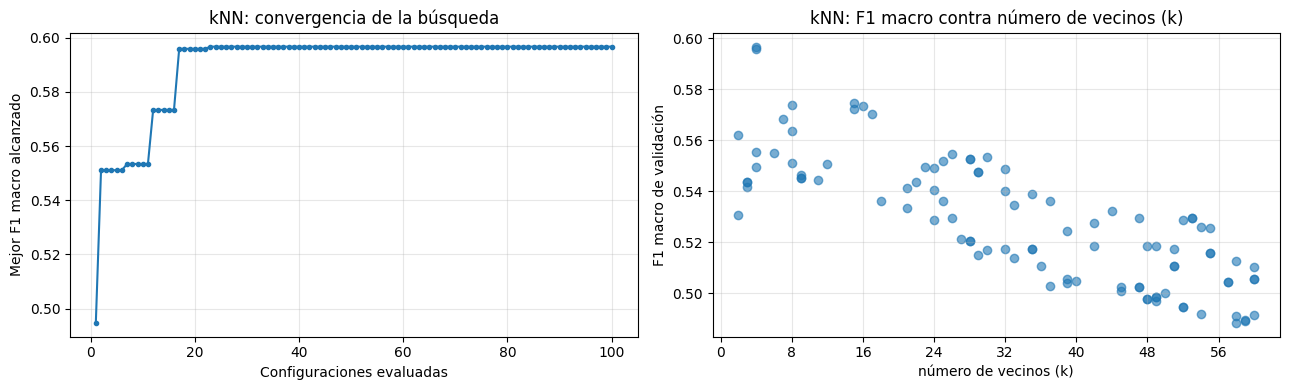

count    mean     max
nominales     distancia                       
con nominales euclidean     28  0.5198  0.5554
              manhattan     27  0.5229  0.5740
sin nominales euclidean     14  0.5183  0.5547
              manhattan     31  0.5454  0.5967

In [76]:
graficar_busqueda("kNN", "modelo__n_neighbors", "número de vecinos (k)", entero=True)

r = pd.DataFrame(busqueda_knn.cv_results_)
r["nominales"] = ["con nominales" if "nominales" in str(p["prep"]) else "sin nominales" for p in r["params"]]
r["distancia"] = [p["modelo__metric"] for p in r["params"]]
display(r.groupby(["nominales", "distancia"])["mean_test_score"].agg(["count", "mean", "max"]).round(4))

### Resultados de kNN

La mejor configuración usa **distancia Manhattan**, **k = 4**, vecinos ponderados por distancia y el preprocesamiento sin atributos nominales. Con esto se obtuvo un **F1 macro de 0.5967 ± 0.0177**, el resultado más bajo hasta ahora y también el que más varía entre pliegues.

Al observar la gráfica de convergencia, vemos que el mejor resultado aparece en la configuración 23 y después prácticamente no mejora, lo que indica que la búsqueda llegó a una meseta.

También se observa que **k es el hiperparámetro que más influye**. Con pocos vecinos, entre 3 y 20, el F1 llega aproximadamente a 0.57–0.60, pero al aumentar k el desempeño baja hasta cerca de 0.51. Esto puede deberse al desbalance de clases: al considerar más vecinos, aumenta la probabilidad de que predomine *Graduate*, que es la clase más frecuente, y el modelo deja de identificar bien *Enrolled*.

Por último, la distancia Manhattan funcionó mejor que la euclidiana y quitar los atributos nominales también mejoró el resultado. Esto muestra que en kNN agregar más variables no siempre ayuda, ya que algunas pueden meter ruido en la distancia. Esto también ayuda a explicar por qué kNN queda por debajo del árbol, que puede ignorar variables poco útiles.

## 6. Máquinas de soporte vectorial (SVM)

El SVM busca la frontera que separa a las clases con el mayor margen posible, y con un kernel puede construir fronteras no lineales sin tener que crear nuevas variables a mano. Al igual que kNN, el SVM con kernel RBF depende de distancias entre estudiantes, por lo que los atributos numéricos se estandarizan. Como el SVM está pensado para dos clases, scikit-learn resuelve el problema de tres clases entrenando un clasificador por cada par de clases (uno contra uno) y la predicción final se decide por votación.

A diferencia de kNN, en este caso sí conservamos los atributos nominales codificados con one-hot. En kNN la decisión depende solo de unos cuantos vecinos, y las columnas del one-hot alteraban quiénes eran esos vecinos. En cambio, el SVM construye la frontera considerando a todos los estudiantes de entrenamiento, entonces la información de los nominales, como la carrera o el modo de ingreso, termina aportando más de lo que estorba. Esto lo comprobamos al final de esta fase comparando las mejores configuraciones con y sin atributos nominales.

Construimos el Pipeline con el preprocesamiento base escalado y el SVM. El espacio de búsqueda se divide en dos partes. En la primera se usa el kernel RBF, donde se optimizan C, que controla qué tanto se castigan los errores en el entrenamiento (un C grande ajusta más los datos y un C pequeño deja una frontera más suave), y gamma, que controla qué tan lejos llega la influencia de cada estudiante de entrenamiento (un gamma grande hace la frontera muy local y puede sobreajustar). En la segunda se usa el kernel lineal, que solo depende de C. En ambas partes se prueban los pesos balanceados por clase. Como el SVM tarda más en entrenarse que los modelos anteriores, se evaluaron 60 configuraciones.

In [77]:
from sklearn.svm import SVC

pipe_svm = Pipeline([
    ("prep", preprocesador(escalar=True)),
    ("modelo", SVC(random_state=SEED)),
])

espacio_svm = [
    {
        "modelo__kernel": ["rbf"],
        "modelo__C": loguniform(1e-2, 1e2),
        "modelo__gamma": loguniform(1e-4, 1e0),
        "modelo__class_weight": [None, "balanced"],
    },
    {
        "modelo__kernel": ["linear"],
        "modelo__C": loguniform(1e-3, 1e1),
        "modelo__class_weight": [None, "balanced"],
    },
]

busqueda_svm = buscar("SVM", pipe_svm, espacio_svm, n_iter=60)

SVM: 60 configuraciones evaluadas
  F1 macro = 0.6828 ± 0.0052
  Tiempo   = 419.4 s
  Mejores hiperparámetros: {'modelo__C': np.float64(25.12779099948729), 'modelo__class_weight': 'balanced', 'modelo__gamma': np.float64(0.00210664860170422), 'modelo__kernel': 'rbf'}


Graficamos la convergencia de la búsqueda y el F1 macro contra gamma para las configuraciones con kernel RBF, coloreando cada punto según su valor de C, ya que el efecto de gamma depende de C. Las configuraciones con kernel lineal no aparecen en esta gráfica porque no usan gamma. También mostramos el mejor resultado para cada combinación de kernel y pesos por clase.

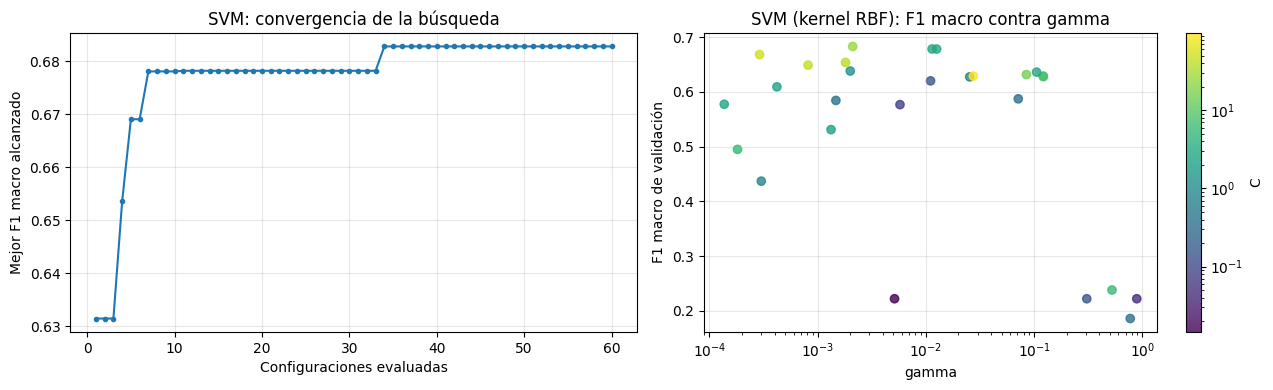

count    mean     max
kernel pesos                          
linear None         16  0.5919  0.6546
       balanced     17  0.6568  0.6770
rbf    None         15  0.5199  0.6537
       balanced     12  0.5613  0.6828

In [78]:
from matplotlib.colors import LogNorm

r = pd.DataFrame(busqueda_svm.cv_results_)
r["kernel"] = [p["modelo__kernel"] for p in r["params"]]
r["pesos"] = [str(p["modelo__class_weight"]) for p in r["params"]]
r["C"] = pd.to_numeric(r["param_modelo__C"], errors="coerce")
r["gamma"] = pd.to_numeric(r["param_modelo__gamma"], errors="coerce")
f1 = r["mean_test_score"].to_numpy()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].plot(np.arange(1, len(f1) + 1), np.maximum.accumulate(f1), marker=".")
ax[0].set_xlabel("Configuraciones evaluadas")
ax[0].set_ylabel("Mejor F1 macro alcanzado")
ax[0].set_title("SVM: convergencia de la búsqueda")
ax[0].grid(alpha=0.3)

rbf = r[r["kernel"] == "rbf"]
puntos = ax[1].scatter(rbf["gamma"], rbf["mean_test_score"], c=rbf["C"],
                       cmap="viridis", norm=LogNorm(), alpha=0.8)
fig.colorbar(puntos, ax=ax[1], label="C")
ax[1].set_xscale("log")
ax[1].set_xlabel("gamma")
ax[1].set_ylabel("F1 macro de validación")
ax[1].set_title("SVM (kernel RBF): F1 macro contra gamma")
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

display(r.groupby(["kernel", "pesos"])["mean_test_score"].agg(["count", "mean", "max"]).round(4))

Para justificar la decisión de conservar los atributos nominales, evaluamos las mejores configuraciones de cada kernel con y sin ellos, usando los mismos pliegues. El preprocesamiento sin nominales es el mismo que se definió para kNN.

In [79]:
from sklearn.base import clone

mejores = {
    "RBF (mejor)": busqueda_svm.best_params_,
    "Lineal (mejor)": r[r["kernel"] == "linear"].sort_values("mean_test_score").iloc[-1]["params"],
}

filas = []
for nombre, params in mejores.items():
    for etiqueta, prep in [("con nominales", preprocesador(escalar=True)),
                           ("sin nominales", prep_knn_sin_nominales)]:
        pipe = clone(pipe_svm).set_params(**params)
        pipe.set_params(prep=prep)
        f1_cv = cross_val_score(pipe, X, y, cv=FOLDS, scoring="f1_macro", n_jobs=-1)
        filas.append({"configuración": nombre, "preprocesamiento": etiqueta,
                      "F1 macro": round(f1_cv.mean(), 4)})

display(pd.DataFrame(filas).pivot(index="configuración", columns="preprocesamiento", values="F1 macro"))

preprocesamiento,con nominales,sin nominales
configuración,,
Lineal (mejor),0.6770,0.6505
RBF (mejor),0.6828,0.6578


### Resultados del SVM

La mejor configuración usa el kernel RBF con C ≈ 25, gamma ≈ 0.0021 y pesos balanceados por clase, con un F1 macro de 0.6828 ± 0.0052. Es el mejor resultado hasta ahora y también el de menor variación entre pliegues, aunque la búsqueda fue la más lenta de todas.

En la gráfica de convergencia se observa que el F1 sube rápido en las primeras 7 configuraciones y la última mejora ocurre en la configuración 34. Esa mejora es de apenas 0.005, que está dentro de la desviación estándar entre pliegues, y después la curva queda plana durante las 26 configuraciones restantes, entonces podemos decir que la búsqueda llegó a una meseta.

En la gráfica de gamma se ve que es el hiperparámetro más influyente, pero su efecto depende de C. Con gamma mayor a 0.1 el F1 cae hasta valores cercanos a 0.40, porque cada estudiante de entrenamiento solo influye en una zona muy pequeña y el modelo se ajusta demasiado. Los mejores resultados aparecen con gamma entre 0.001 y 0.01 combinados con un C grande, es decir, una frontera suave pero que castiga bastante los errores.

En la tabla se observa que los pesos balanceados mejoran ambos kernels, lo cual tiene sentido por el desbalance de las clases. Es interesante que el kernel lineal con pesos balanceados llega a 0.677, muy cerca del RBF, así pues una frontera casi lineal ya separa bien a las clases y el kernel no lineal solo agrega una pequeña mejora. Esto nos da una pista de lo que podemos esperar de la regresión logística, que también construye fronteras lineales.

Por último, al comparar con y sin atributos nominales, el SVM pierde alrededor de 0.025 de F1 al quitarlos, lo contrario de lo que ocurrió con kNN. Esto confirma que conservarlos fue la decisión correcta para este modelo.

## 7. Regresión logística

La regresión logística estima la probabilidad de que un estudiante pertenezca a cada clase a partir de una combinación lineal de sus atributos, por lo que construye fronteras lineales entre las clases. Para el problema de tres clases, scikit-learn ajusta un modelo multinomial que estima las tres probabilidades al mismo tiempo. Los atributos numéricos se estandarizan, ya que la regularización castiga el tamaño de los coeficientes y, sin escalar, un atributo con valores grandes necesitaría coeficientes pequeños y quedaría menos castigado que los demás. Los atributos nominales se conservan codificados con one-hot, igual que en el SVM.

El espacio de búsqueda incluye C, que es el inverso de la fuerza de la regularización (un C pequeño castiga mucho los coeficientes y simplifica el modelo), el tipo de regularización y los pesos por clase. Para probar los distintos tipos de regularización en una sola búsqueda se usó la penalización elastic net con el parámetro `l1_ratio`, donde 0 corresponde a la regularización L2 (Ridge), que reduce todos los coeficientes, 1 corresponde a la regularización L1 (Lasso), que puede dejar coeficientes en cero y de esta forma descartar atributos, y los valores intermedios combinan ambas. Se evaluaron 60 configuraciones.

El único solver de scikit-learn que admite elastic net con tres clases es `saga`. Con su tolerancia por defecto el entrenamiento era muy lento, entonces se usó una tolerancia de 10⁻³, con la cual el modelo converge en menos de 400 iteraciones. En versiones recientes de scikit-learn el parámetro `penalty` está en desuso y genera una advertencia, pero sigue funcionando, por lo que se oculta esa advertencia.

In [80]:
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings("ignore", message="'penalty' was deprecated")
warnings.filterwarnings("ignore", message="Inconsistent values")

pipe_lr = Pipeline([
    ("prep", preprocesador(escalar=True)),
    ("modelo", LogisticRegression(penalty="elasticnet", solver="saga",
                                  max_iter=2000, tol=1e-3, random_state=SEED)),
])

espacio_lr = {
    "modelo__C": loguniform(1e-3, 1e2),
    "modelo__l1_ratio": [0.0, 0.25, 0.5, 0.75, 1.0],
    "modelo__class_weight": [None, "balanced"],
}

busqueda_lr = buscar("Regresión logística", pipe_lr, espacio_lr, n_iter=60)

Regresión logística: 60 configuraciones evaluadas
  F1 macro = 0.6824 ± 0.0084
  Tiempo   = 232.9 s
  Mejores hiperparámetros: {'modelo__C': np.float64(0.17885301261862016), 'modelo__class_weight': 'balanced', 'modelo__l1_ratio': 0.75}


Graficamos la convergencia de la búsqueda y el F1 macro contra C, que resultó ser el hiperparámetro más influyente, coloreando cada punto según su tipo de regularización. También mostramos el mejor resultado para cada combinación de regularización y pesos por clase.

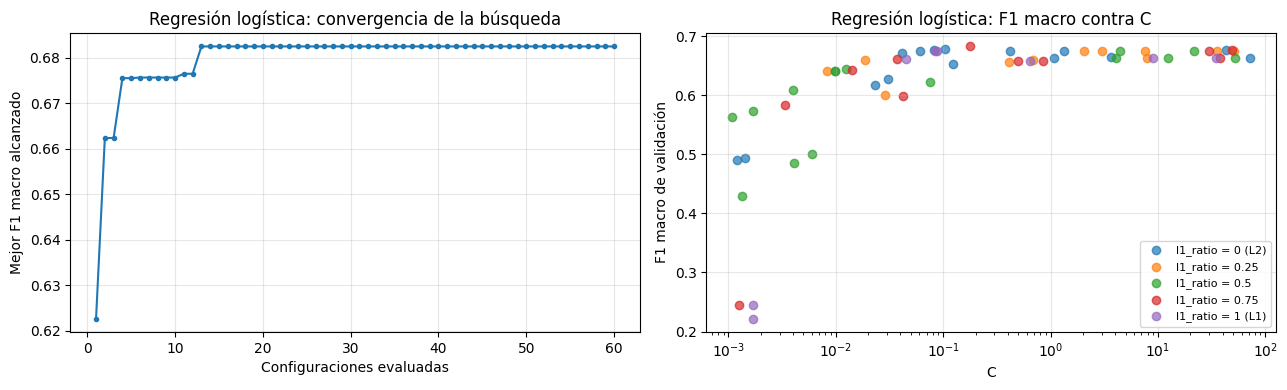

count    mean     max
l1_ratio pesos                          
0.00     None          8  0.6089  0.6638
         balanced      7  0.6751  0.6778
0.25     None          4  0.6443  0.6623
         balanced      7  0.6678  0.6753
0.50     None          7  0.5750  0.6632
         balanced      8  0.6274  0.6755
0.75     None          4  0.6443  0.6631
         balanced      7  0.5949  0.6824
1.00     None          4  0.5516  0.6631
         balanced      4  0.5639  0.6753

In [81]:
r = pd.DataFrame(busqueda_lr.cv_results_)
r["C"] = pd.to_numeric(r["param_modelo__C"])
r["l1_ratio"] = pd.to_numeric(r["param_modelo__l1_ratio"])
r["pesos"] = [str(p["modelo__class_weight"]) for p in r["params"]]
f1 = r["mean_test_score"].to_numpy()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].plot(np.arange(1, len(f1) + 1), np.maximum.accumulate(f1), marker=".")
ax[0].set_xlabel("Configuraciones evaluadas")
ax[0].set_ylabel("Mejor F1 macro alcanzado")
ax[0].set_title("Regresión logística: convergencia de la búsqueda")
ax[0].grid(alpha=0.3)

for valor, grupo in r.groupby("l1_ratio"):
    etiqueta = {0.0: "0 (L2)", 1.0: "1 (L1)"}.get(valor, f"{valor}")
    ax[1].scatter(grupo["C"], grupo["mean_test_score"], alpha=0.7, label=f"l1_ratio = {etiqueta}")
ax[1].set_xscale("log")
ax[1].set_xlabel("C")
ax[1].set_ylabel("F1 macro de validación")
ax[1].set_title("Regresión logística: F1 macro contra C")
ax[1].legend(fontsize=8)
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

display(r.groupby(["l1_ratio", "pesos"])["mean_test_score"].agg(["count", "mean", "max"]).round(4))

### Resultados de la regresión logística

La mejor configuración usa C ≈ 0.18, `l1_ratio` = 0.75 (una regularización principalmente L1 con una parte de L2) y pesos balanceados por clase, con un F1 macro de 0.6824 ± 0.0084. Este resultado prácticamente empata con el SVM (0.6828), y la diferencia entre ambos es mucho menor que la desviación estándar entre pliegues.

En la gráfica de convergencia se observa que el mejor F1 se alcanza en la configuración 13 y después la curva queda plana durante las 47 configuraciones restantes, entonces la búsqueda llegó a una meseta.

En la gráfica de C se ve que es el hiperparámetro más influyente. Con C menor a 0.01 la regularización es tan fuerte que casi todos los coeficientes se reducen a cero y el F1 cae hasta valores cercanos a 0.50, mientras que a partir de C ≈ 0.1 el desempeño se estabiliza alrededor de 0.67–0.68 y aumentar C ya no ayuda. Esto indica que el modelo no necesita mucha regularización, pero tampoco se beneficia de quitarla por completo.

En la tabla se observa que el tipo de regularización tiene poco efecto cuando C está en un buen rango, ya que las mejores configuraciones de L2 (0.678), L1 (0.675) y las combinaciones intermedias quedan muy cerca entre sí. En cambio, los pesos balanceados sí mejoran el resultado en todos los casos, lo cual tiene sentido por el desbalance de las clases.

Es interesante que un modelo lineal y sencillo alcance el mismo desempeño que el SVM con kernel RBF, así pues las clases se pueden separar bastante bien con fronteras lineales. Además, la regresión logística tiene la ventaja de que sus coeficientes se pueden interpretar y de que su búsqueda fue más rápida.

## 8. Comparación de los clasificadores

En esta fase comparamos los cinco clasificadores con su mejor configuración. La métrica principal es el F1 macro, reportado con su media y su desviación estándar entre los 5 pliegues. Además calculamos la sensibilidad y la especificidad de cada clase, y el tiempo que tardó cada búsqueda. Como los cinco modelos se evaluaron con los mismos pliegues, también podemos comparar su desempeño pliegue por pliegue.

Para cada clasificador obtenemos el F1 macro de cada pliegue a partir de los resultados de su búsqueda. Para la sensibilidad y la especificidad generamos predicciones de validación cruzada, es decir, cada estudiante es clasificado por el modelo entrenado en los pliegues donde él no estaba, y con esas predicciones construimos la matriz de confusión. La sensibilidad de una clase es la proporción de estudiantes de esa clase que el modelo identifica correctamente, y la especificidad es la proporción de estudiantes de las otras clases que el modelo no confunde con ella. Estas predicciones se guardan porque las usaremos en la siguiente fase.

In [82]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix

CLASES = ["Dropout", "Enrolled", "Graduate"]
PRED_CV = {}
F1_PLIEGUES = {}
filas = []

for nombre, res in RESULTADOS.items():
    busqueda = res["busqueda"]
    i = busqueda.best_index_
    f1_pliegues = np.array([busqueda.cv_results_[f"split{k}_test_score"][i] for k in range(len(FOLDS))])
    F1_PLIEGUES[nombre] = f1_pliegues

    pred = cross_val_predict(busqueda.best_estimator_, X, y, cv=FOLDS, n_jobs=-1)
    PRED_CV[nombre] = pred
    cm = confusion_matrix(y, pred, labels=CLASES)

    fila = {"Clasificador": nombre,
            "F1 macro": f1_pliegues.mean(),
            "Desv. est.": f1_pliegues.std()}
    for j, clase in enumerate(CLASES):
        vp = cm[j, j]
        fn = cm[j, :].sum() - vp
        fp = cm[:, j].sum() - vp
        vn = cm.sum() - vp - fn - fp
        fila[f"Sens. {clase}"] = vp / (vp + fn)
        fila[f"Esp. {clase}"] = vn / (vn + fp)
    fila["Tiempo (s)"] = res["tiempo"]
    filas.append(fila)

comparacion = pd.DataFrame(filas).set_index("Clasificador").sort_values("F1 macro", ascending=False)
display(comparacion.round(4))

,F1 macro,Desv. est.,Sens. Dropout,Esp. Dropout,Sens. Enrolled,Esp. Enrolled,Sens. Graduate,Esp. Graduate,Tiempo (s)
Clasificador,,,,,,,,,
SVM,0.6828,0.0052,0.6719,0.9301,0.6079,0.8144,0.7968,0.8454,419.4324
Regresión logística,0.6824,0.0084,0.6974,0.9238,0.5748,0.8258,0.7957,0.8386,232.8837
Árbol,0.6457,0.0102,0.6192,0.9430,0.6000,0.7600,0.7504,0.8341,76.0547
Naive Bayes,0.6202,0.0099,0.7036,0.8297,0.4189,0.8664,0.7459,0.7980,53.7628
kNN,0.5967,0.0177,0.6236,0.8972,0.2850,0.9015,0.8630,0.6665,129.7639


Graficamos el F1 macro de cada clasificador con su desviación estándar, junto con la línea base del clasificador al azar estratificado. También graficamos el F1 macro de cada clasificador en cada pliegue. Como todos usan los mismos pliegues, esta gráfica permite ver si un modelo es mejor de forma consistente o solo en promedio.

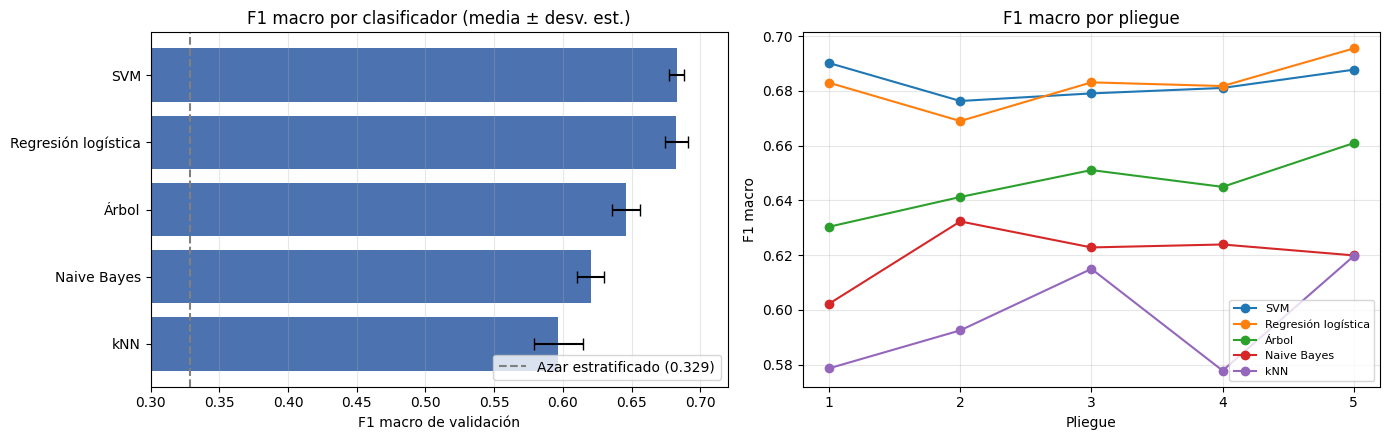

,Árbol,Naive Bayes,kNN,SVM,Regresión logística
Pliegue 1,0.6303,0.6022,0.5786,0.6901,0.6829
Pliegue 2,0.6412,0.6323,0.5925,0.6763,0.6689
Pliegue 3,0.6510,0.6228,0.6149,0.6790,0.6831
Pliegue 4,0.6449,0.6239,0.5778,0.6810,0.6817
Pliegue 5,0.6609,0.6199,0.6196,0.6877,0.6955


In [83]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

orden = comparacion.index[::-1]
ax[0].barh(orden, comparacion.loc[orden, "F1 macro"],
           xerr=comparacion.loc[orden, "Desv. est."], capsize=4, color="#4c72b0")
ax[0].axvline(0.329, ls="--", color="gray", label="Azar estratificado (0.329)")
ax[0].set_xlim(0.3, 0.72)
ax[0].set_xlabel("F1 macro de validación")
ax[0].set_title("F1 macro por clasificador (media ± desv. est.)")
ax[0].legend(loc="lower right")
ax[0].grid(alpha=0.3, axis="x")

for nombre in comparacion.index:
    ax[1].plot(range(1, len(FOLDS) + 1), F1_PLIEGUES[nombre], marker="o", label=nombre)
ax[1].set_xticks(range(1, len(FOLDS) + 1))
ax[1].set_xlabel("Pliegue")
ax[1].set_ylabel("F1 macro")
ax[1].set_title("F1 macro por pliegue")
ax[1].legend(fontsize=8)
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

display(pd.DataFrame(F1_PLIEGUES, index=[f"Pliegue {k + 1}" for k in range(len(FOLDS))]).round(4))

### Resultados de la comparación

Los cinco clasificadores superan claramente al clasificador al azar (0.329), pero hay dos grupos bien definidos. El SVM (0.6828 ± 0.0052) y la regresión logística (0.6824 ± 0.0084) quedan en primer lugar, después el árbol de decisión (0.6457), Naive Bayes (0.6202) y al final kNN (0.5967).

La diferencia entre el SVM y la regresión logística es de apenas 0.0004, que es mucho menor que la desviación estándar de ambos. En la gráfica por pliegue se observa que el SVM es mejor en dos pliegues y la regresión logística en los otros tres, entonces no podemos afirmar que uno sea realmente superior al otro. Con base en el criterio de la consigna, el mejor clasificador es el SVM por tener el F1 macro promedio más alto y la menor variación entre pliegues, pero la regresión logística es una alternativa igual de válida.

Al revisar la sensibilidad por clase se confirma que *Enrolled* es la clase más difícil. El SVM (0.608) y el árbol (0.600) son los que mejor la identifican, mientras que kNN solo reconoce al 28.5 % de estos estudiantes. Esto es consistente con lo que vimos en la fase 5, ya que kNN tiende a clasificar como *Graduate* a la mayoría de los estudiantes, lo cual se refleja en su sensibilidad alta para *Graduate* (0.863) pero con la especificidad más baja para esa misma clase (0.666).

En el caso de *Dropout*, que es la clase de mayor interés para la institución, la regresión logística (0.697) y Naive Bayes (0.704) tienen la sensibilidad más alta, pero Naive Bayes lo logra a costa de una especificidad mucho menor (0.830), es decir, marca como desertores a más estudiantes que no lo son. El SVM tiene una sensibilidad un poco menor para *Dropout* (0.672) pero con una especificidad de 0.930.

Por otro lado, el árbol tiene la especificidad más baja para *Enrolled* (0.760), lo cual indica que, por los pesos balanceados, predice esta clase con mucha frecuencia y se equivoca con estudiantes de las otras clases.

En cuanto al tiempo, el SVM fue la búsqueda más lenta, seguido de la regresión logística, mientras que el árbol y Naive Bayes fueron los más rápidos. Así pues, la regresión logística ofrece prácticamente el mismo desempeño que el SVM en menos tiempo y con un modelo que se puede interpretar.

## 9. Matriz de confusión del mejor clasificador

En esta fase analizamos los errores del mejor clasificador, el SVM, usando las predicciones de validación cruzada que se generaron en la fase anterior. Nos enfocamos en la clase *Dropout*, ya que identificar a los estudiantes que van a desertar es el objetivo principal del problema, y buscamos responder con qué clase se confunde y por qué.

Mostramos la matriz de confusión en dos versiones: con el número de estudiantes y normalizada por fila. En la versión normalizada cada fila suma 1, de esta forma la diagonal corresponde a la sensibilidad de cada clase y los valores fuera de la diagonal indican hacia qué clase se van los errores.

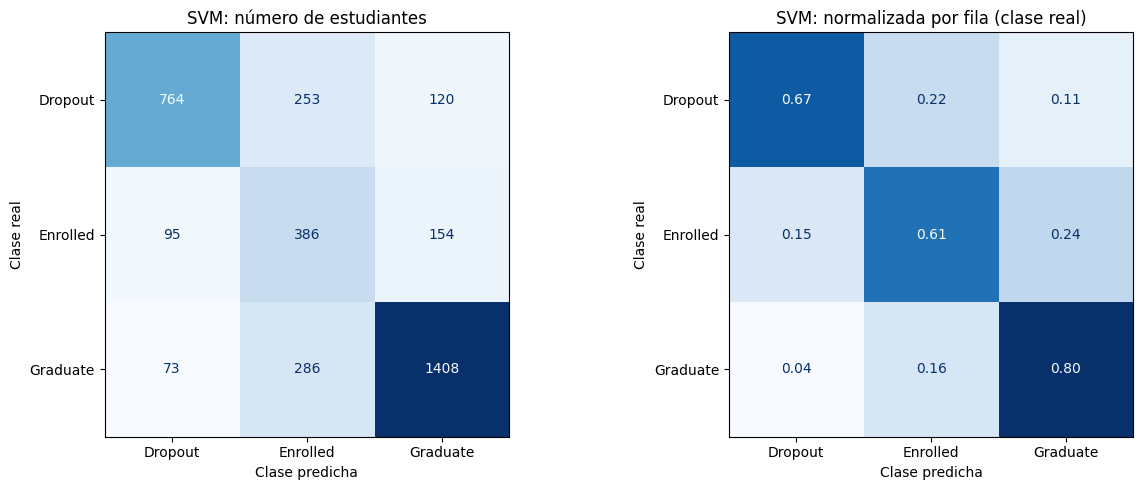

In [84]:
from sklearn.metrics import ConfusionMatrixDisplay

MEJOR = comparacion.index[0]
pred_mejor = PRED_CV[MEJOR]

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(y, pred_mejor, labels=CLASES, ax=ax[0],
                                        cmap="Blues", colorbar=False)
ax[0].set_title(f"{MEJOR}: número de estudiantes")

ConfusionMatrixDisplay.from_predictions(y, pred_mejor, labels=CLASES, ax=ax[1],
                                        cmap="Blues", colorbar=False,
                                        normalize="true", values_format=".2f")
ax[1].set_title(f"{MEJOR}: normalizada por fila (clase real)")

for a in ax:
    a.set_xlabel("Clase predicha")
    a.set_ylabel("Clase real")

plt.tight_layout()
plt.show()

Para entender por qué el modelo se equivoca con algunos desertores, dividimos a los estudiantes que realmente desertaron según la clase que les asignó el modelo, y comparamos sus atributos del primer semestre con los de los estudiantes que realmente siguen inscritos o que se graduaron. Además de los promedios, calculamos la proporción de unidades aprobadas respecto a las inscritas y el porcentaje de estudiantes que no aprobaron ninguna unidad.

In [85]:
real = y.to_numpy()
grupo = np.select(
    [(real == "Dropout") & (pred_mejor == "Dropout"),
     (real == "Dropout") & (pred_mejor == "Enrolled"),
     (real == "Dropout") & (pred_mejor == "Graduate"),
     real == "Enrolled",
     real == "Graduate"],
    ["Dropout → Dropout", "Dropout → Enrolled", "Dropout → Graduate",
     "Enrolled (real)", "Graduate (real)"],
    default="",
)

analisis = train.assign(grupo=grupo)
analisis["Proporción aprobadas"] = (analisis["Curricular units 1st sem (approved)"]
                                     / analisis["Curricular units 1st sem (enrolled)"].replace(0, np.nan))
analisis["Sin unidades aprobadas"] = (analisis["Curricular units 1st sem (approved)"] == 0).astype(int)

columnas = ["Curricular units 1st sem (enrolled)", "Curricular units 1st sem (approved)",
            "Proporción aprobadas", "Sin unidades aprobadas",
            "Curricular units 1st sem (grade)", "Tuition fees up to date", "Debtor",
            "Scholarship holder", "Age at enrollment"]

orden_grupos = ["Dropout → Dropout", "Dropout → Enrolled", "Dropout → Graduate",
                "Enrolled (real)", "Graduate (real)"]
tabla_errores = analisis.groupby("grupo")[columnas].mean().loc[orden_grupos].T
tabla_errores.loc["Número de estudiantes"] = analisis["grupo"].value_counts()[orden_grupos]
display(tabla_errores.round(2))

grupo,Dropout → Dropout,Dropout → Enrolled,Dropout → Graduate,Enrolled (real),Graduate (real)
Curricular units 1st sem (enrolled),5.62,5.83,7.18,6.01,6.68
Curricular units 1st sem (approved),1.58,3.55,6.68,4.33,6.25
Proporción aprobadas,0.25,0.60,0.94,0.71,0.93
Sin unidades aprobadas,0.56,0.06,0.03,0.09,0.04
Curricular units 1st sem (grade),5.25,11.20,12.55,11.13,12.62
Tuition fees up to date,0.52,0.98,0.98,0.95,0.99
Debtor,0.29,0.08,0.08,0.11,0.04
Scholarship holder,0.06,0.10,0.30,0.17,0.38
Age at enrollment,27.59,23.06,22.78,22.33,21.79
Número de estudiantes,764.00,253.00,120.00,635.00,1767.00


### Análisis de la clase *Dropout*

De los 1137 estudiantes que desertaron, el SVM identificó correctamente a 764 (67.2 %). De los que no identificó, 253 (22.3 %) fueron clasificados como *Enrolled* y 120 (10.6 %) como *Graduate*, entonces la principal confusión de *Dropout* es con *Enrolled*. En sentido contrario, el modelo casi no confunde a otros estudiantes con desertores, ya que solo 95 estudiantes inscritos y 73 graduados fueron clasificados como *Dropout*, lo cual coincide con la especificidad alta de esta clase (0.930).

Al comparar los atributos del primer semestre se entiende la razón de estos errores. Los desertores que el modelo sí identificó tienen señales muy claras: el 56 % no aprobó ninguna unidad, en promedio aprobaron solo el 25 % de las unidades inscritas, casi la mitad no tenía las colegiaturas al corriente, el 29 % tenía deudas con la institución y en promedio ingresaron a los 27.6 años, es decir, mayores que el resto.

En cambio, los desertores que el modelo clasificó como *Enrolled* se parecen mucho a los estudiantes que realmente siguen inscritos. Aprobaron en promedio el 60 % de sus unidades (contra 71 % de los inscritos reales), tienen un promedio de calificaciones casi idéntico (11.2 contra 11.1), el 98 % tiene sus colegiaturas al corriente y su edad es similar. Así pues, al cierre del primer semestre estos estudiantes muestran el perfil de alguien que va atrasado pero sigue avanzando, y su deserción ocurre más adelante por razones que todavía no se reflejan en los datos.

Los 120 desertores clasificados como *Graduate* son todavía más difíciles de detectar, ya que en el primer semestre aprobaron el 94 % de sus unidades, tienen calificaciones de 12.6 y el 30 % tiene beca, es decir, su desempeño es igual al de un estudiante que se gradúa. Con la información disponible al cierre del primer semestre no hay forma de distinguirlos.

Con base en esto podemos decir que el modelo detecta muy bien la deserción temprana, la de estudiantes que desde el primer semestre muestran problemas académicos o económicos, pero no puede anticipar la deserción que ocurre después. Esto sugiere que esperar al cierre del segundo semestre podría ayudar a detectar a parte de estos estudiantes, lo cual evaluaremos en la siguiente fase.

## 10. ¿Conviene esperar al cierre del segundo semestre?

En esta fase estimamos cuánto mejoraría el mejor clasificador si, en lugar de decidir al cierre del primer semestre, se esperara al cierre del segundo. Para esto usamos únicamente el conjunto de entrenamiento, que es el único que tiene los atributos del segundo semestre, y evaluamos el SVM con la misma configuración de hiperparámetros y los mismos pliegues, agregando las 6 columnas del segundo semestre a los atributos numéricos. De esta forma la única diferencia entre ambas evaluaciones es la información disponible.

Construimos el preprocesamiento incluyendo las columnas del segundo semestre, que también se estandarizan, y lo colocamos en una copia del mejor modelo. Después calculamos el F1 macro de cada pliegue y las predicciones de validación cruzada, y comparamos el F1, la sensibilidad y la especificidad contra los resultados al cierre del primer semestre. También contamos cuántos desertores identifica correctamente el modelo en cada caso.

In [86]:
from sklearn.base import clone

prep_2sem = ColumnTransformer([
    ("nominales", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10), NOMINALES),
    ("binarias", "passthrough", BINARIAS),
    ("numericas", StandardScaler(), NUMERICAS + SEGUNDO_SEM),
])

modelo_2sem = clone(RESULTADOS[MEJOR]["busqueda"].best_estimator_).set_params(prep=prep_2sem)

f1_2sem = cross_val_score(modelo_2sem, X_2sem, y, cv=FOLDS, scoring="f1_macro", n_jobs=-1)
pred_2sem = cross_val_predict(modelo_2sem, X_2sem, y, cv=FOLDS, n_jobs=-1)

def sens_esp(pred):
    cm = confusion_matrix(y, pred, labels=CLASES)
    fila = {}
    for j, clase in enumerate(CLASES):
        vp = cm[j, j]
        fn = cm[j, :].sum() - vp
        fp = cm[:, j].sum() - vp
        vn = cm.sum() - vp - fn - fp
        fila[f"Sens. {clase}"] = vp / (vp + fn)
        fila[f"Esp. {clase}"] = vn / (vn + fp)
    return fila

def desertores_detectados(pred):
    return int(((y == "Dropout") & (pred == "Dropout")).sum())

tabla_2sem = pd.DataFrame({
    "Cierre 1er semestre": {"F1 macro": F1_PLIEGUES[MEJOR].mean(),
                            "Desv. est.": F1_PLIEGUES[MEJOR].std(),
                            **sens_esp(PRED_CV[MEJOR]),
                            "Desertores detectados": desertores_detectados(PRED_CV[MEJOR])},
    "Cierre 2do semestre": {"F1 macro": f1_2sem.mean(),
                            "Desv. est.": f1_2sem.std(),
                            **sens_esp(pred_2sem),
                            "Desertores detectados": desertores_detectados(pred_2sem)},
})
tabla_2sem["Diferencia"] = tabla_2sem["Cierre 2do semestre"] - tabla_2sem["Cierre 1er semestre"]
display(tabla_2sem.round(4))

display(pd.DataFrame({"1er semestre": F1_PLIEGUES[MEJOR],
                      "2do semestre": f1_2sem,
                      "Diferencia": f1_2sem - F1_PLIEGUES[MEJOR]},
                     index=[f"Pliegue {k + 1}" for k in range(len(FOLDS))]).round(4))

,Cierre 1er semestre,Cierre 2do semestre,Diferencia
F1 macro,0.6828,0.7130,0.0302
Desv. est.,0.0052,0.0093,0.0040
Sens. Dropout,0.6719,0.7124,0.0405
Esp. Dropout,0.9301,0.9359,0.0058
Sens. Enrolled,0.6079,0.6362,0.0283
Esp. Enrolled,0.8144,0.8320,0.0176
Sens. Graduate,0.7968,0.8200,0.0232
Esp. Graduate,0.8454,0.8679,0.0226
Desertores detectados,764.0000,810.0000,46.0000


,1er semestre,2do semestre,Diferencia
Pliegue 1,0.6901,0.7046,0.0145
Pliegue 2,0.6763,0.7230,0.0467
Pliegue 3,0.6790,0.7076,0.0285
Pliegue 4,0.6810,0.7255,0.0445
Pliegue 5,0.6877,0.7045,0.0167


Comparamos las matrices de confusión normalizadas por fila al cierre de cada semestre, para ver en qué clases se concentra la mejora.

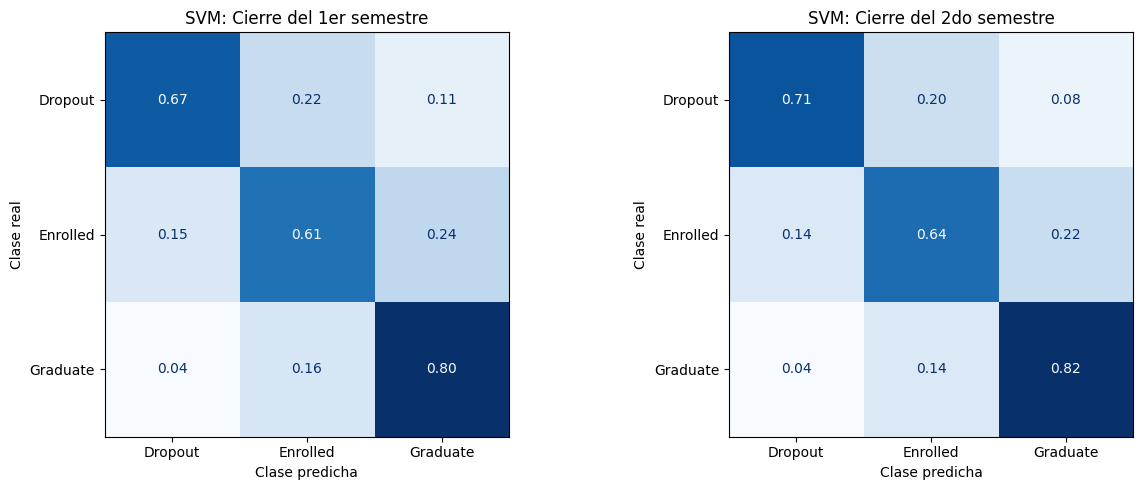

In [87]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

for a, pred, titulo in [(ax[0], PRED_CV[MEJOR], "Cierre del 1er semestre"),
                        (ax[1], pred_2sem, "Cierre del 2do semestre")]:
    ConfusionMatrixDisplay.from_predictions(y, pred, labels=CLASES, ax=a, cmap="Blues",
                                            colorbar=False, normalize="true", values_format=".2f")
    a.set_title(f"{MEJOR}: {titulo}")
    a.set_xlabel("Clase predicha")
    a.set_ylabel("Clase real")

plt.tight_layout()
plt.show()

En las matrices de confusión se observa que la mejora en *Dropout* viene principalmente de los desertores que antes se confundían con *Graduate*, que bajan de 11 % a 8 %, mientras que la confusión con *Enrolled* solo baja de 22 % a 20 %. Esto indica que algunos estudiantes que en el primer semestre tenían un desempeño similar al de un graduado muestran una caída en el segundo semestre, y es esa caída la que permite detectarlos. Por otro lado, la confusión entre *Enrolled* y *Graduate* también se reduce un poco en ambas direcciones, aunque sigue siendo el principal error del modelo en esas dos clases.

Para entender de dónde viene la mejora, comparamos el porcentaje de estudiantes de cada clase que no aprobó ninguna unidad en el primer y en el segundo semestre.

In [88]:
sin_aprobar = pd.DataFrame({
    "1er semestre": train.groupby("Target")["Curricular units 1st sem (approved)"].apply(lambda s: (s == 0).mean()),
    "2do semestre": train.groupby("Target")["Curricular units 2nd sem (approved)"].apply(lambda s: (s == 0).mean()),
})
display((100 * sin_aprobar).round(1).rename_axis("% sin unidades aprobadas"))

,1er semestre,2do semestre
% sin unidades aprobadas,,
Dropout,39.4,50.7
Enrolled,9.0,9.1
Graduate,3.7,3.6


### Resultados e interpretación

Al agregar los atributos del segundo semestre, el F1 macro del SVM pasa de 0.6828 a 0.7130, una mejora de 0.030 que es más de tres veces la desviación estándar entre pliegues. Además la mejora aparece en los cinco pliegues, entonces podemos decir que es real y no producto de la partición de los datos. La sensibilidad aumenta en las tres clases: en *Dropout* pasa de 0.672 a 0.712, en *Enrolled* de 0.608 a 0.636 y en *Graduate* de 0.797 a 0.820. En términos concretos, el modelo identifica correctamente a 810 desertores en lugar de 764, es decir, 46 estudiantes más de un total de 1137.

Al revisar de dónde viene esta mejora, se observa que el 39.4 % de los desertores no aprobó ninguna unidad en el primer semestre, pero en el segundo semestre esa proporción sube al 50.7 %, mientras que en los estudiantes inscritos y graduados casi no cambia. Esto indica que una parte de los desertores que en el primer semestre se parecían a los inscritos empiezan a dejar de aprobar en el segundo semestre, y es justo esa señal la que permite detectarlos. Así pues, la información del segundo semestre no revela algo nuevo sobre el estudiante, sino que muestra que el proceso de deserción ya comenzó.

Con base en esto, consideramos que no conviene esperar al cierre del segundo semestre para tomar la decisión. El objetivo del modelo es intervenir a tiempo, y esperar un semestre significa retrasar la atención de los 764 desertores que ya se pueden identificar al cierre del primero, a cambio de detectar a 46 estudiantes más que, para ese momento, en su mayoría ya dejaron de aprobar materias. Además, los estudiantes que abandonan durante el segundo semestre no se beneficiarían de esperar.

Una alternativa que vale la pena considerar es no elegir entre ambos momentos, sino usar el modelo en dos etapas: una primera predicción al cierre del primer semestre para intervenir con los casos más claros, y una segunda revisión al cierre del segundo semestre con el modelo que incluye esa información, para detectar a los estudiantes que en la primera etapa no mostraban señales de riesgo.

## 11. Clasificador final y predicciones sobre el conjunto de prueba

Con base en la comparación de la fase 8, el clasificador final es el SVM con kernel RBF, ya que obtuvo el F1 macro promedio más alto y la menor variación entre pliegues. En esta fase lo entrenamos con todo el conjunto de entrenamiento, generamos las predicciones para los 885 estudiantes del conjunto de prueba y guardamos el archivo CSV que se entrega. Es importante recordar que el conjunto de prueba no tiene la variable *Target*, por lo que no podemos medir el desempeño del modelo sobre él, solo verificar que las predicciones sean coherentes.

Hacemos una copia del mejor modelo con sus hiperparámetros y lo entrenamos con los 3539 estudiantes del conjunto de entrenamiento, usando únicamente los 30 atributos disponibles al cierre del primer semestre. Aunque la búsqueda de hiperparámetros ya entrena el mejor modelo con todos los datos al terminar, se entrena de nuevo de forma explícita para que quede claro qué modelo genera las predicciones.

In [89]:
modelo_final = clone(RESULTADOS[MEJOR]["busqueda"].best_estimator_)

inicio = time.perf_counter()
modelo_final.fit(X, y)
print(f"Modelo final: {MEJOR}")
print(f"Hiperparámetros: { {k: v for k, v in RESULTADOS[MEJOR]['busqueda'].best_params_.items() if k != 'prep'} }")
print(f"Tiempo de entrenamiento: {time.perf_counter() - inicio:.1f} s")

Modelo final: SVM
Hiperparámetros: {'modelo__C': np.float64(25.12779099948729), 'modelo__class_weight': 'balanced', 'modelo__gamma': np.float64(0.00210664860170422), 'modelo__kernel': 'rbf'}
Tiempo de entrenamiento: 1.5 s


Generamos las predicciones para el conjunto de prueba y construimos el archivo con las dos columnas que pide la entrega, `id` y `Target`. Como la variable objetivo del dataset viene con la primera letra en mayúscula, los valores se convierten a minúsculas para que queden como `dropout`, `enrolled` y `graduate`. El archivo se guarda con una ruta relativa en la misma carpeta del notebook.

In [90]:
pred_test = modelo_final.predict(X_test)

predicciones = pd.DataFrame({
    "id": test["id"],
    "Target": pd.Series(pred_test).str.lower(),
})

predicciones.to_csv("predicciones.csv", index=False)
display(predicciones.head())

,id,Target
0,6,graduate
1,12,graduate
2,15,graduate
3,18,enrolled
4,19,graduate


Antes de entregar verificamos que el archivo cumpla con el formato: que tenga exactamente 885 filas y las columnas `id` y `Target`, que no haya identificadores repetidos ni faltantes, que los identificadores coincidan con los del conjunto de prueba y que solo aparezcan los tres valores permitidos. Para esto leemos el archivo guardado, y no la variable en memoria, de esta forma comprobamos lo que realmente se va a entregar. También comparamos la distribución de las clases predichas con la de entrenamiento y con la de las predicciones de validación cruzada.

In [91]:
archivo = pd.read_csv("predicciones.csv")

assert archivo.shape == (885, 2), "El archivo no tiene 885 filas y 2 columnas"
assert list(archivo.columns) == ["id", "Target"], "Las columnas no son id y Target"
assert archivo["id"].is_unique, "Hay identificadores repetidos"
assert archivo.notna().all().all(), "Hay valores faltantes"
assert set(archivo["id"]) == set(test["id"]), "Los identificadores no coinciden con el conjunto de prueba"
assert set(archivo["Target"]) <= {"dropout", "enrolled", "graduate"}, "Hay valores no permitidos en Target"
print("El archivo predicciones.csv cumple con el formato de entrega.")

distribuciones = pd.DataFrame({
    "Entrenamiento (real)": y.str.lower().value_counts(normalize=True),
    "Validación cruzada (predicho)": pd.Series(PRED_CV[MEJOR]).str.lower().value_counts(normalize=True),
    "Prueba (predicho)": archivo["Target"].value_counts(normalize=True),
})
display((100 * distribuciones).round(1).rename_axis("% de estudiantes"))

El archivo predicciones.csv cumple con el formato de entrega.


,Entrenamiento (real),Validación cruzada (predicho),Prueba (predicho)
% de estudiantes,,,
dropout,32.1,26.3,25.0
enrolled,17.9,26.1,26.0
graduate,49.9,47.5,49.0


### Resultados del clasificador final

El archivo `predicciones.csv` cumple con el formato de entrega: 885 estudiantes, sin identificadores repetidos y con los valores en minúsculas. El modelo clasificó a 434 estudiantes como *graduate* (49.0 %), 230 como *enrolled* (26.0 %) y 221 como *dropout* (25.0 %).

Al comparar con la distribución real del conjunto de entrenamiento (49.9 % *graduate*, 17.9 % *enrolled* y 32.1 % *dropout*), se observa que el modelo predice más estudiantes inscritos y menos desertores de los que esperaríamos. Esto no indica un problema con el conjunto de prueba, ya que las predicciones de validación cruzada muestran el mismo patrón: el modelo predice *enrolled* con más frecuencia por los pesos balanceados, que le dan más importancia a la clase minoritaria, y parte de los desertores quedan clasificados como inscritos, como vimos en la fase 9. Así pues, la distribución de las predicciones sobre el conjunto de prueba es coherente con el comportamiento que el modelo tuvo durante la validación.

Con base en la validación cruzada esperamos que el F1 macro sobre el conjunto de prueba sea cercano a 0.68, aunque puede variar porque se trata de estudiantes que el modelo no ha visto.

### Desempeño de cada clasificador

**Árbol de decisión (0.6457).** El árbol obtuvo un desempeño intermedio. Su principal ventaja es que se puede interpretar como un conjunto de reglas, lo cual sería útil para que la institución explique por qué un estudiante fue marcado en riesgo. Sin embargo, el mejor árbol necesitó una poda fuerte (al menos 38 estudiantes por hoja) para no ajustarse demasiado a los datos de entrenamiento, y sus fronteras en forma de escalón no logran separar las clases tan bien como los modelos que construyen fronteras suaves. Por otro lado, los pesos balanceados lo llevaron a predecir *Enrolled* con mucha frecuencia, lo que le dio una buena sensibilidad para esa clase pero la especificidad más baja (0.760).

**Naive Bayes (0.6202).** Su desempeño estuvo limitado por el supuesto de independencia, que en este dataset no se cumple, ya que varios atributos del primer semestre dicen prácticamente lo mismo (unidades inscritas, evaluadas y aprobadas). Es interesante que la variante Bernoulli con los atributos numéricos discretizados funcionó mucho mejor que la variante gaussiana, lo cual muestra que en este caso discretizar fue mejor decisión que asumir normalidad. Naive Bayes tuvo la sensibilidad más alta para *Dropout* (0.704), pero a costa de marcar como desertores a más estudiantes que no lo eran.

**kNN (0.5967).** Fue el clasificador con el peor desempeño y la mayor variación entre pliegues. kNN depende por completo de la distancia entre estudiantes, y en este problema eso le afectó de dos formas: las columnas del one-hot alteraban qué estudiantes eran considerados vecinos, por lo que funcionó mejor sin los atributos nominales, y conforme aumentaba el número de vecinos la mayoría de ellos pertenecían a la clase *Graduate*, que es la más frecuente. Por esta razón kNN solo identificó al 28.5 % de los estudiantes inscritos, y al no admitir pesos por clase no había forma de compensar el desbalance.

**SVM (0.6828).** Fue el mejor clasificador, con el F1 macro más alto y la menor variación entre pliegues, por lo que se eligió como clasificador final. A diferencia de kNN, el SVM sí se benefició de los atributos nominales, y los pesos balanceados mejoraron su desempeño en ambos kernels. Su desventaja es que fue la búsqueda más lenta y que su modelo no se puede interpretar. Además, el kernel lineal llegó a 0.677, muy cerca del kernel RBF, entonces la ventaja de construir una frontera no lineal fue pequeña.

**Regresión logística (0.6824).** Prácticamente empató con el SVM, con una diferencia mucho menor que la desviación estándar entre pliegues y ganando en tres de los cinco pliegues. Esto confirma lo que sugería el kernel lineal del SVM: las clases se pueden separar bastante bien con fronteras lineales. Además, la regresión logística tiene la ventaja de que sus coeficientes se pueden interpretar y de que su búsqueda fue más rápida, así pues, en un uso real dentro de la institución podría ser una mejor opción que el SVM.


En esta última fase discutimos el desempeño de cada clasificador en este problema y las decisiones que más influyeron en los resultados.

### Conclusiones

Con base en los resultados, podemos identificar algunos patrones que se repitieron en los cinco clasificadores. El primero es que los pesos balanceados por clase mejoraron el F1 macro en todos los modelos que los admiten, lo cual tiene sentido porque el F1 macro le da el mismo peso a la clase *Enrolled*, que es la minoritaria. El segundo es que el preprocesamiento adecuado depende del modelo, ya que los atributos nominales ayudaron al SVM pero perjudicaron a kNN, y discretizar fue mejor que asumir normalidad en Naive Bayes. Entonces no existe un preprocesamiento que sea el mejor para todos los modelos.

La clase *Enrolled* fue la más difícil de predecir para todos los clasificadores. Esto puede explicarse porque *Enrolled* no describe un resultado final sino un estado intermedio: son estudiantes que al final de la duración normal de su carrera todavía no se gradúan ni desertan, y que más adelante podrían terminar de cualquiera de las dos formas. Por lo tanto, es natural que se confundan tanto con los desertores como con los graduados.

En cuanto a la clase *Dropout*, el análisis de la fase 9 mostró que el modelo identifica muy bien la deserción temprana, la de estudiantes que desde el primer semestre muestran problemas académicos o económicos, pero no puede anticipar la deserción de estudiantes que en el primer semestre tienen un desempeño normal. Esperar al cierre del segundo semestre mejora el F1 macro en 0.030 y permite detectar a 46 desertores más, pero consideramos que no conviene esperar, ya que retrasaría la intervención con los estudiantes que ya se pueden identificar. Una alternativa es usar el modelo en dos etapas, una al cierre de cada semestre.



## Declaración de uso de inteligencia artificial

En la elaboración de esta práctica se utilizó **Claude (Anthropic)** como herramienta de apoyo. A continuación se describe su uso:

**Usos de la herramienta:**

- **Revisión de los datos:** inspección inicial de los archivos de entrenamiento y prueba para identificar la estructura del dataset, las columnas del segundo semestre que solo aparecen en entrenamiento, el desbalance de las clases, las categorías del conjunto de prueba que no aparecen en entrenamiento y el formato de la variable objetivo.
- **Planeación:** propuesta de la organización del notebook en fases, desde la carga de los datos hasta el clasificador final.
- **Código:** propuesta del código en Python (pandas, numpy, scikit-learn, matplotlib)
- **Decisiones metodológicas:** propuestas de decisiones como la agrupación de categorías poco frecuentes, la exclusión de los atributos nominales en kNN, la discretización para Naive Bayes, el uso de elastic net en la regresión logística y la forma de estimar la mejora al cierre del segundo semestre.
- **Redacción:** borradores de las descripciones en Markdown de cada fase, de cada bloque de código y de las interpretaciones de los resultados, redactados a partir de ejemplos de mi forma de escribir.
- **Depuración:** diagnóstico y corrección de errores durante la ejecución del notebook algunos causados por diferencias entre versiones de las librerías.

**Trabajo propio:**

- Carga de los datos y ejecución de todo el código en Google Colab, así como la revisión de cada salida antes de continuar con el siguiente paso.
- Comparación de mis resultados con los valores esperados en cada paso.
- Revisión y ajuste de los textos para que coincidieran con los resultados obtenidos en mi ejecución.
- Toma de decisiones a lo largo del análisis.

Considero que la IA funcionó como una guía y apoyo para entender el proceso, y que puedo explicar cada paso y decisión del trabajo.